# 像素腦讀論文 P05｜Segment Anything（SAM）
用 Meta 官方釋出的程式 [segment-anything](https://github.com/facebookresearch/segment-anything)（Apache 2.0）和最小的 `vit_b` 權重，點一點貓咪照片。

論文：Kirillov 等，Segment Anything，ICCV 2023，https://arxiv.org/abs/2304.02643

貓咪照片：AdinaVoicu，CC0，Wikimedia Commons。

> 提示：Colab 可以在「執行階段 → 變更執行階段類型」選 GPU，影像編碼器會快很多；只用處理器也跑得動，只是要等十幾秒。

In [1]:
!pip -q install segment-anything
import os, time, urllib.request
import numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator
if not os.path.exists("cat.png"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/pixelbraintw/pixelbrain-code/main/p05-sam/cat.png", "cat.png")
CKPT = "sam_vit_b_01ec64.pth"
if not os.path.exists(CKPT):
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/" + CKPT, CKPT)
device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry["vit_b"](checkpoint=CKPT).to(device).eval()
img = np.array(Image.open("cat.png").convert("RGB"))
print("裝置：", device, "｜參數（百萬）：", round(sum(p.numel() for p in sam.parameters()) / 1e6, 1))

裝置： cpu ｜參數（百萬）： 93.7


## 1. 先拍 X 光：影像編碼器每張圖只跑一次

In [2]:
pred = SamPredictor(sam)
t0 = time.perf_counter(); pred.set_image(img); print(f"影像編碼器：{time.perf_counter() - t0:.2f} 秒")
print("特徵圖形狀：", tuple(pred.get_image_embedding().shape))

影像編碼器：22.67 秒
特徵圖形狀： (1, 256, 64, 64)


## 2. 點一下：一個點，三個答案
改改看 `POINT` 的位置（800×800 照片上的座標）。

點一下：242.0 毫秒


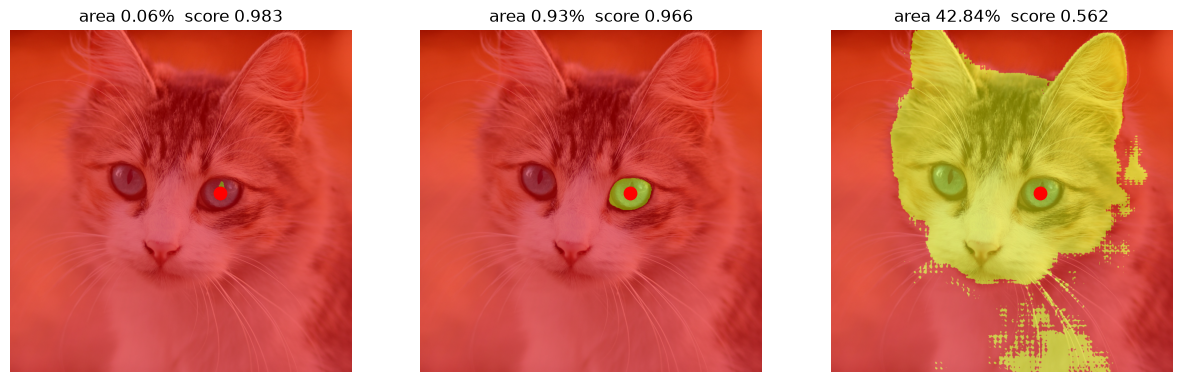

In [3]:
POINT = [490, 380]
t0 = time.perf_counter()
masks, scores, _ = pred.predict(point_coords=np.array([POINT]), point_labels=np.array([1]), multimask_output=True)
print(f"點一下：{(time.perf_counter() - t0) * 1000:.1f} 毫秒")
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, i in zip(ax, np.argsort([m.sum() for m in masks])):
    a.imshow(img); a.imshow(masks[i], alpha=0.5, cmap="autumn"); a.scatter(*POINT, c="red", s=80)
    a.set_title(f"area {masks[i].mean() * 100:.2f}%  score {scores[i]:.3f}"); a.axis("off")
plt.show()

## 3. 框一個框

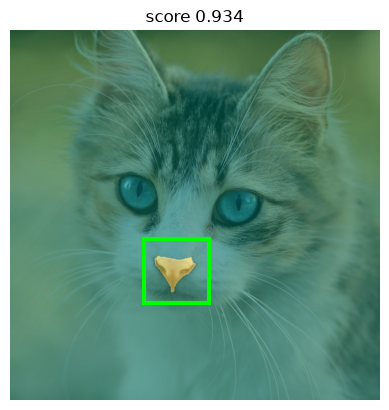

In [4]:
BOX = [290, 450, 430, 590]
m, s, _ = pred.predict(box=np.array(BOX), multimask_output=False)
plt.imshow(img); plt.imshow(m[0], alpha=0.5, cmap="summer"); plt.gca().add_patch(plt.Rectangle(BOX[:2], BOX[2] - BOX[0], BOX[3] - BOX[1], fill=False, ec="lime", lw=3)); plt.title(f"score {s[0]:.3f}"); plt.axis("off"); plt.show()

## 4. 分割一切：32×32 個點
官方預設會把分數不夠高（`pred_iou_thresh=0.88`）和不穩定（`stability_score_thresh=0.95`）的遮罩丟掉。試試看把兩個門檻調低，會多出幾塊？

4 塊，360.4 秒


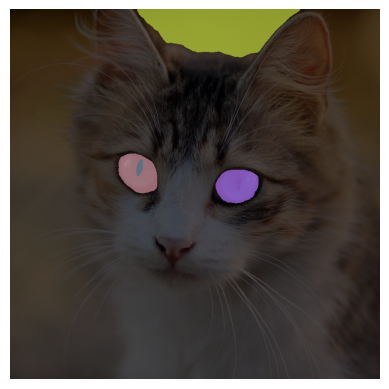

In [5]:
gen = SamAutomaticMaskGenerator(sam, points_per_side=32)
t0 = time.perf_counter(); auto = gen.generate(img); print(f"{len(auto)} 塊，{time.perf_counter() - t0:.1f} 秒")
canvas = img.astype(float) * 0.35
rng = np.random.default_rng(5)
for a in sorted(auto, key=lambda a: -a["area"]):
    canvas[a["segmentation"]] = canvas[a["segmentation"]] * 0.3 + rng.integers(60, 255, 3) * 0.7
plt.imshow(canvas.clip(0, 255).astype(np.uint8)); plt.axis("off"); plt.show()

## 🧪 自己玩玩看

1. 把 `pred_iou_thresh` 改成 0.7、`stability_score_thresh` 改成 0.8，再分割一切一次。
2. 上傳你自己的照片（左邊資料夾圖示 → 上傳），把 `cat.png` 換成你的檔名。
3. 在 `predict` 加一個背景點（`point_labels` 填 0），看看遮罩怎麼變。

有問題歡迎到影片留言區問像素腦！